In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/data.yaml
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/100b_jpg.rf.5518a9f45a7eb2dab98df16d96f223c8.jpg
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/103_jpg.rf.4e2cd87d24cff067a92ed04f9ea95eb4.jpg
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/103a_jpg.rf.7cc93cbc0c8b2a8d89b2a03a7f19eb21.jpg
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/107_jpg.rf.29a741c343edd1f0eb2febb82f61acfe.jpg
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/112_jpg.rf.c122458fdd30c246e2c6b1644a95da76.jpg
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/114a_jpg.rf.ccbe2fff01c6fbd7d21b126e5424a607.jpg
/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/test/images/120_jpg.rf.3f4ff813cfcfdf9a6f76911017956bb3.jpg
/kaggle/input/datasets/prakhars

### 准备工作

In [2]:
!pip install ultralytics
!pip install supervision

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 3.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 52.4 MB/s  0:00:00m0:00:01:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [supervision] [supervision]


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from ultralytics import YOLO
import supervision as sv
from IPython.display import Video
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights & Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### 模型下载

In [4]:
model = YOLO('yolo11n.pt')


image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/95_jpg.rf.74f9f88bf63476b360c8d5a4f0caa5c6.jpg: 640x640 2 cars, 11.0ms
Speed: 82.0ms preprocess, 11.0ms inference, 33.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict
1 label saved to /kaggle/working/runs/detect/predict/labels

image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/619c_jpg.rf.d73b0f415ca6703407dd2fbd021da772.jpg: 640x640 1 car, 12.8ms
Speed: 0.9ms preprocess, 12.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict
2 labels saved to /kaggle/working/runs/detect/predict/labels

image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/945_jpg.rf.24a6a9d00da31d09dc9719ce7d1333f7.jpg: 640x640 (no detections), 10.9ms
Speed: 0.8ms preprocess, 10.9ms inference, 0.6ms postprocess per image at shape 

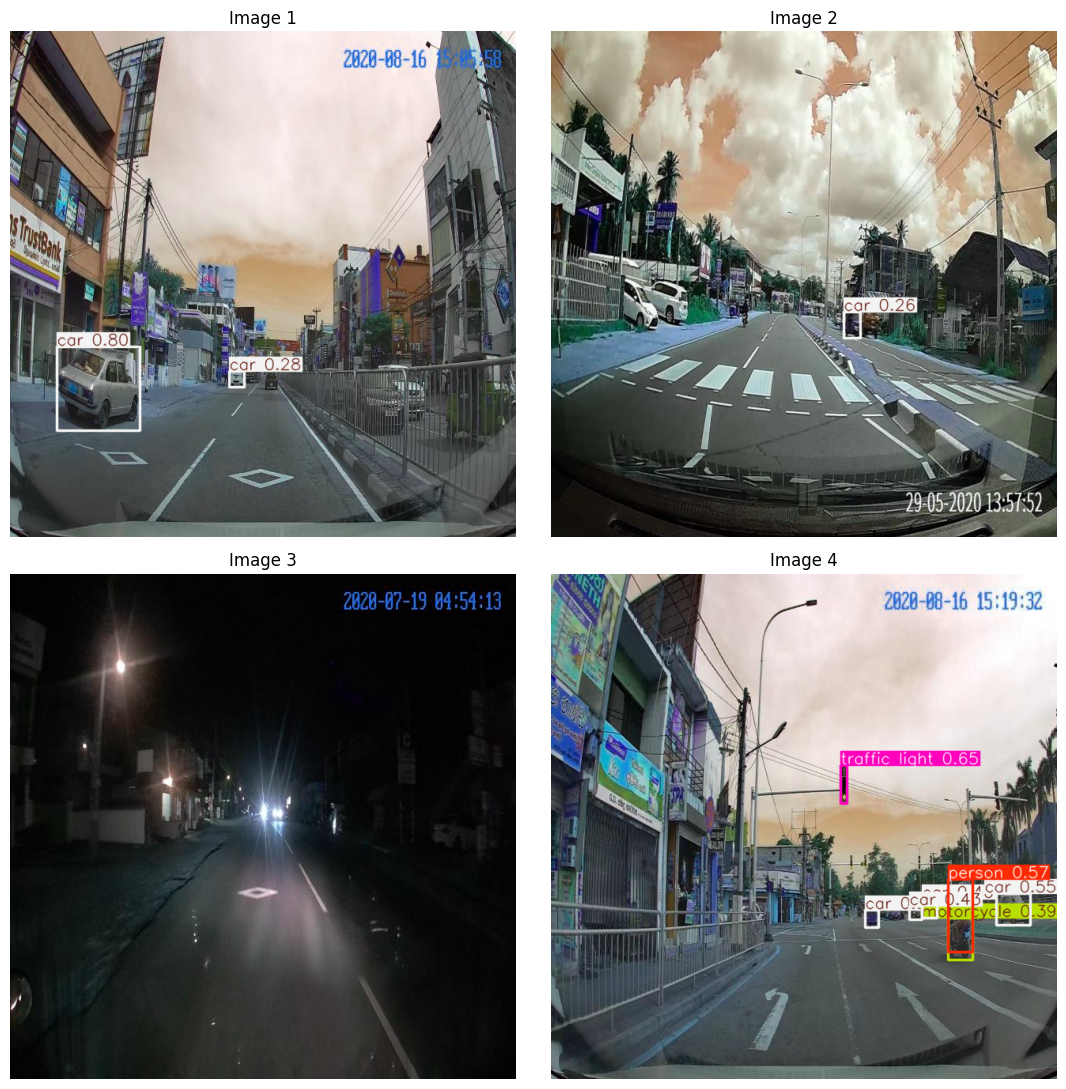

In [5]:
# 设置训练图片目标路径
train_img_dir = '/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images'
# 设置样本数量
num_samples = 4
# 获取训练图片文件列表
image_files = os.listdir(train_img_dir)
# 随机选择指定数量的图片文件作为测试样本
test_imgs = random.sample(image_files, num_samples)

# 创建一个包含 2 * 2 子图的图形，用于展示图片
fig, axes = plt.subplots(2, 2, figsize = (11, 11))
# 遍历每个选定的测试图片
for i in range(num_samples):
    # 获取当前图片文件名
    image = test_imgs[i]
    # 选择当前子图
    ax = axes[i // 2, i % 2]
    # 使用 yolo 模型对图片进行预测，并保存预测结果和标签
    result_predict = model.predict(
        source = os.path.join(train_img_dir, image),
        save = True,
        save_txt = True
    )
    # 在当前子图上展示预测结果图片
    ax.imshow(result_predict[0].plot())
    # 设置当前子图的标题
    ax.set_title(f'Image {i + 1}')
    # 关闭当前子图的坐标轴显示
    ax.axis('off')
# 调整子图布局，确保没有重叠
plt.tight_layout()
# 展示所有图片
plt.show()

### 模型训练

In [6]:
results = model.train(
    data = '/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/data.yaml', # 数据集配置文件路径
    epochs = 30
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=6

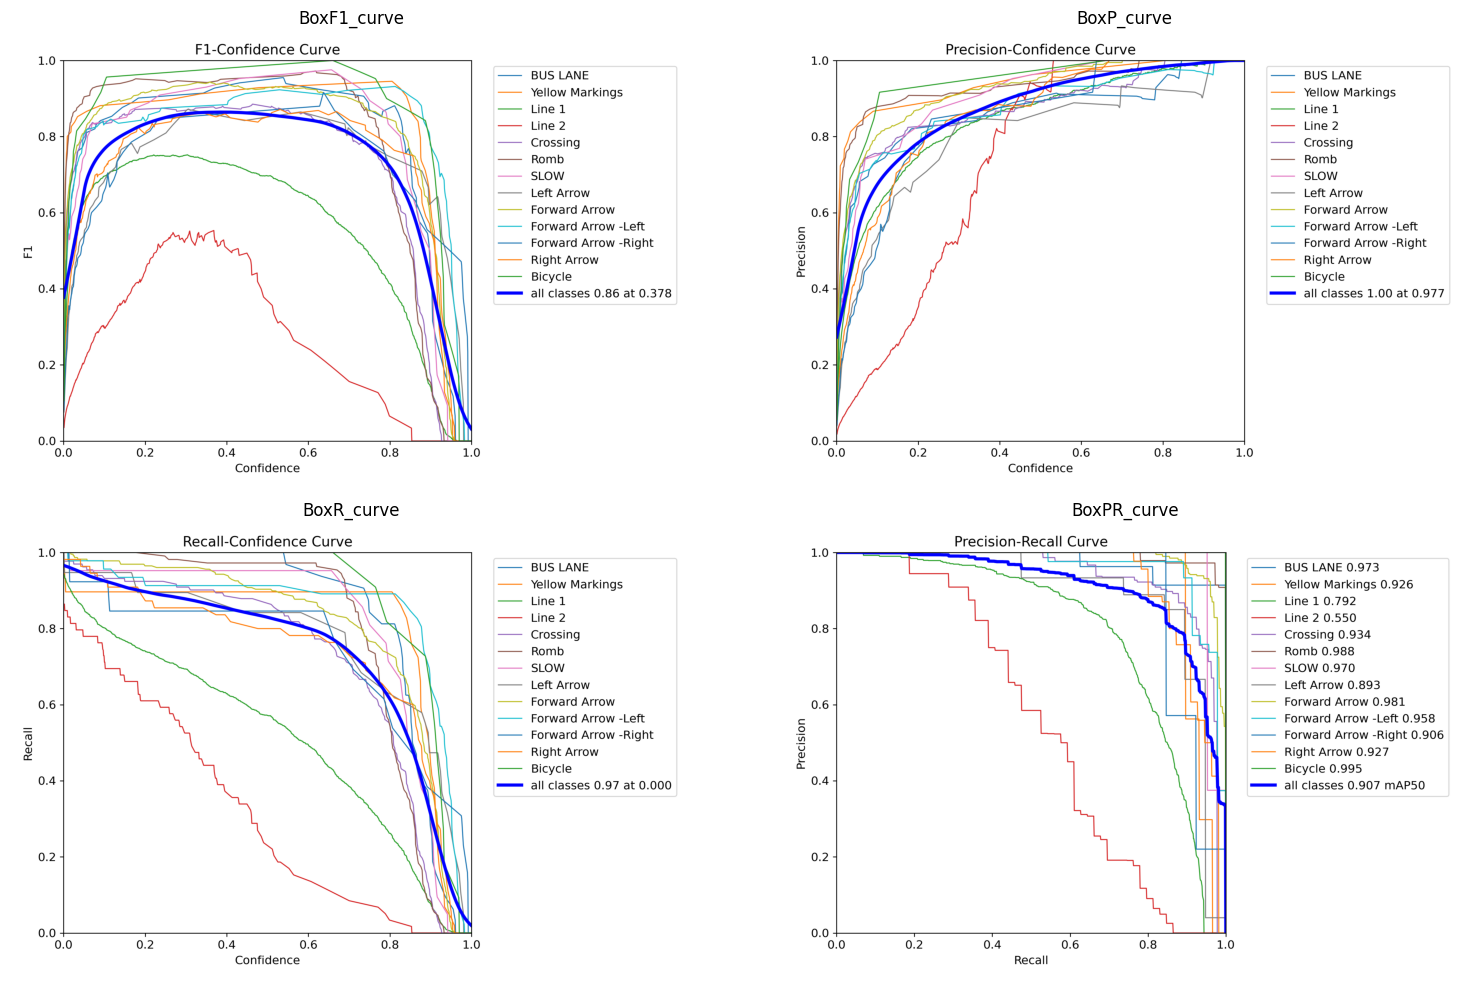

In [8]:
# 指定性能评估曲线的图片所在的目录
directory = '/kaggle/working/runs/detect/train'

# 定义要展示的图片文件名
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

# 创建一个包含 4 张子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便于索引

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        # 设置子图标题为图片文件名（去掉扩展名）
        ax.set_title(os.path.splitext(image_file)[0])
        ax.axis('off')
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

# 调整子图间距
plt.tight_layout()
plt.show()

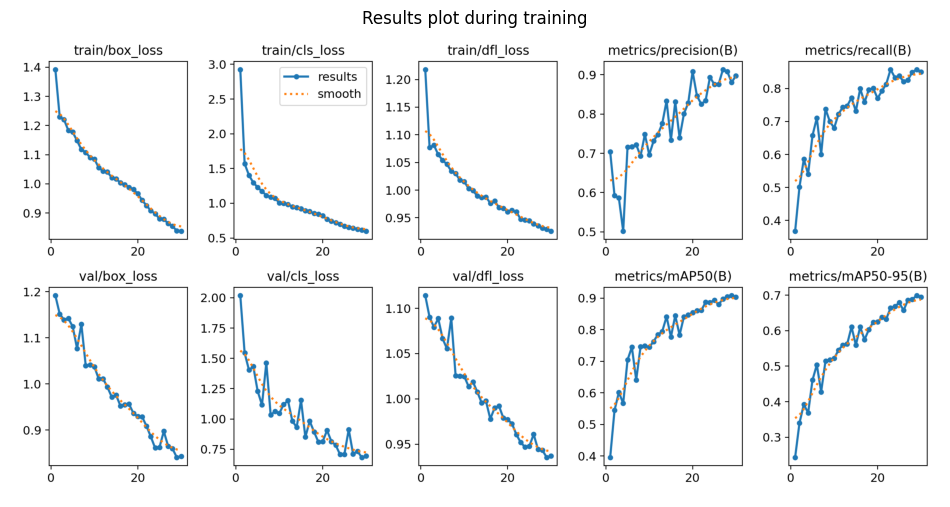

In [9]:
# results.png 图片路径
image_path = '/kaggle/working/runs/detect/train/results.png'
# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并显示图片
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title('Results plot during training')
plt.axis('off')
plt.show()

### 模型验证

In [10]:
# 加载训练好的最优模型
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
# 模型验证
metrics = model.val(
    data = '/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/data.yaml'
)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,599,967 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 127.8±54.4 MB/s, size: 60.0 KB)
val: Scanning /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/valid/labels... 417 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 417/417 739.5it/s 0.6s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 5.8it/s 4.6s0.1s
                   all        417       1966      0.879      0.858      0.908      0.703
              BUS LANE         32         32      0.867          1      0.973      0.731
       Yellow Markings         28         29      0.939      0.897      0.927      0.728
                Line 1        218 

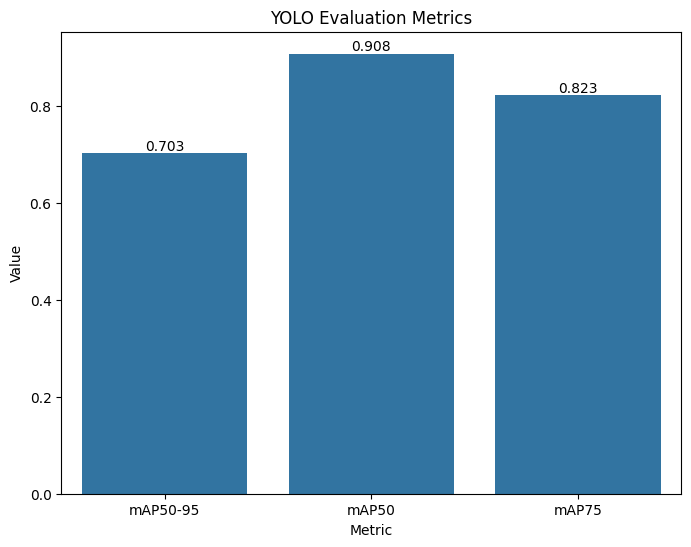

In [12]:
%matplotlib inline
# 创建柱状图
ax = sns.barplot(
    x = ['mAP50-95', 'mAP50', 'mAP75'],
    y = [metrics.box.map, metrics.box.map50, metrics.box.map75]
)
# 设置标题和轴标签
ax.set_title('YOLO Evaluation Metrics')
ax.set_xlabel('Metric')
ax.set_ylabel('Value')
fig = plt.gcf()
fig.set_size_inches(8, 6)
# 在柱状图上添加数值
for p in ax.patches:
    ax.annotate(
        '{:.3f}'.format(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha = 'center',
        va = 'bottom'
    )
# 显示图形
plt.show()

### 模型预测

In [13]:
# 随机对一张图片进行预测
test_img_dir = '/kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images'
num_samples = 1
image_files = os.listdir(test_img_dir)
test_img = random.sample(image_files, num_samples)
model.predict(
    source = os.path.join(test_img_dir, test_img[0]), # 指定用于推理的数据来源
    save = True, # 启用将带有注释的图片或视频保存到文件
    save_txt = True # 将检测结果保存到文本文件中
)


image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/501a_jpg.rf.26e1f53921ea5232d894bdf0fcc360ab.jpg: 640x640 9 Line 1s, 1 Forward Arrow, 1 Forward Arrow -Left, 10.8ms
Speed: 0.9ms preprocess, 10.8ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /kaggle/working/runs/detect/predict-2
1 label saved to /kaggle/working/runs/detect/predict-2/labels


[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 colors: None
 depth: None
 keypoints: None
 masks: None
 names: {0: 'BUS LANE', 1: 'Yellow Markings', 2: 'Line 1', 3: 'Line 2', 4: 'Crossing', 5: 'Romb', 6: 'SLOW', 7: 'Left Arrow', 8: 'Forward Arrow', 9: 'Forward Arrow -Left', 10: 'Forward Arrow -Right', 11: 'Right Arrow', 12: 'Bicycle'}
 obb: None
 orig_img: array([[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [153, 144, 141],
         [152, 143, 140],
         [152, 143, 140]],
 
        [[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [152, 143, 140],
         [152, 143, 140],
         [152, 143, 140]],
 
        [[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [152, 143, 140],
         [151, 142, 139],
         [151, 142, 139]],
 
        ...,
 
        [[ 81,  94,  92],
         [ 77,  90

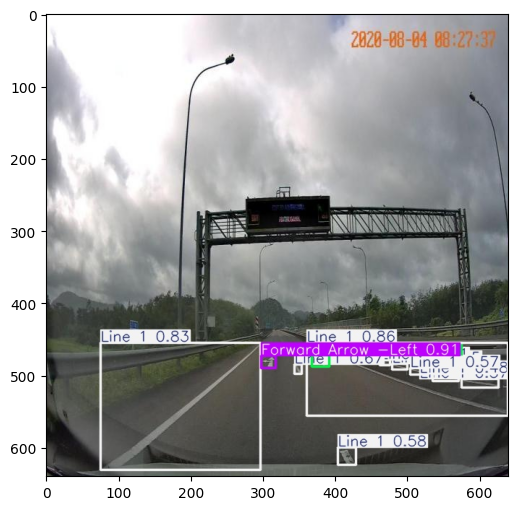

In [15]:
# 图片路径
result_img_dir = '/kaggle/working/runs/detect/predict-2/'
image_files = '501a_jpg.rf.26e1f53921ea5232d894bdf0fcc360ab.jpg' # TODO: 那张随机的测试图片预测的结果图片
# 读取图片
img = plt.imread(os.path.join(result_img_dir, image_files))
plt.figure(figsize = (12, 6))
plt.imshow(img)


image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/297b_jpg.rf.6eb2c9946681aa92a95185690eeb0a77.jpg: 640x640 1 Forward Arrow, 1 Forward Arrow -Left, 10.9ms
Speed: 1.2ms preprocess, 10.9ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/239a_jpg.rf.929b084c6416614164f2624eec9faf02.jpg: 640x640 5 Line 1s, 1 Right Arrow, 10.8ms
Speed: 0.9ms preprocess, 10.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/454b_jpg.rf.cc62a3b63be25ee3626ab5c6bdbf6d65.jpg: 640x640 4 Line 1s, 2 Line 2s, 1 Left Arrow, 1 Forward Arrow, 1 Right Arrow, 10.8ms
Speed: 0.8ms preprocess, 10.8ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/prakharsinghchouhan/dataset-english/archive/train/images/307_jpg.rf.51418

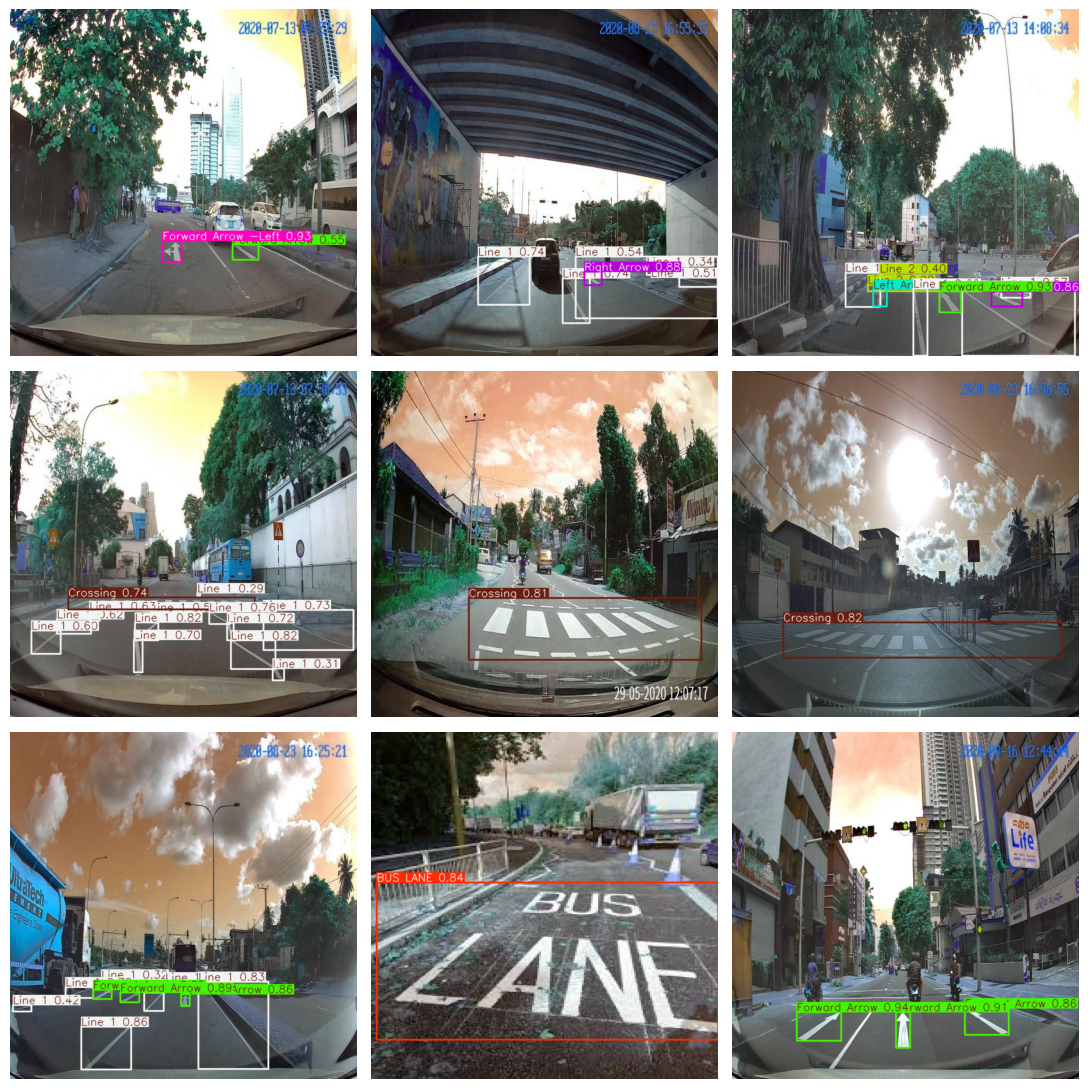

In [16]:
# 定义采样数量
num_samples = 9

# 获取测试图片目录下的所有图片文件名
image_files = os.listdir(test_img_dir)

# 随机选择指定数量的图片文件作为测试图像
test_imgs = random.sample(image_files, num_samples)

# 创建一个 3 * 3 的图幅，用于展示 9 张测试图片的预测结果
fig, axes = plt.subplots(3, 3, figsize = (11, 11))

# 遍历没张测试图片
for i in range(num_samples):
    # 获取当前测试图片的文件名
    image = test_imgs[i]
    # 根据索引确定图片在 3 * 3 图幅中的位置
    ax = axes[i // 3, i % 3]
    # 使用模型对当前测试图片进行预测
    result_predict = model.predict(
        source = os.path.join(test_img_dir, image)
    )
    # 在图幅中的相应位置上展示预测结果图片
    ax.imshow(result_predict[0].plot())
    # 关闭图像坐标轴显示
    ax.axis('off')
# 调整图幅布局，确保图片标题和图片本身不重叠
plt.tight_layout()
# 展示所有测试图片的预测结果
plt.show()

In [17]:
!zip -q -r results.zip /kaggle/working/*